# Mitigation score plots

The **score** of a lever is computed from the size reduction it delivers, with the same `mitigation_*` functions as in the size plots:

`score = (1 - reduction) ** (1 / weight)`

The weights (`LEVER_WEIGHTS` in `smart_size_mitigation_heuristics.py`) are the priorities of the levers: the higher the weight, the milder the penalty and the more the lever is preferred. The final score of a plan is the product of the lever scores.

First the score function itself, then one plot per lever (**n_bin**, **PB**, **hm_cell**, **ROI**, **spws** and **fields**) with the same x-axes as in the size plots. All functions and weights are imported from `smart_size_mitigation_heuristics.py`, so the plots always match what the planner uses.

Figures are saved as PNGs in `PLOT_DIR`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from smart_size_mitigation_heuristics import (
    mitigation_nbin,
    mitigation_pb,
    mitigation_cell,
    mitigation_roi,
    mitigation_fields,
    mitigation_spws,
    lever_score,
    LEVER_WEIGHTS,
)

# Directory for the saved figures: one level above the code directory
# (the directory this notebook lives in). Change the name here if needed.
PLOT_DIR = Path.cwd().parent / "70_results/plots"
PLOT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Saving figures to: {PLOT_DIR}")

# Function to label a curve at a given x position, rotated to match the slope of the curve there
def label_along_curve(ax, x, y, x_label, text, color, side=1, offset_pts=8, fontsize=9):
    """Write `text` next to the curve (x, y) at x = x_label, rotated so that it
    runs parallel to the curve there (the slope is taken in display
    coordinates, i.e. as it looks on the plot). side=+1 puts the label above
    the curve, side=-1 below it. Call after fig.tight_layout(), once the axes
    size is final."""
    x, y = np.asarray(x), np.asarray(y)
    eps = 0.01 * (x[-1] - x[0])
    (px0, py0), (px1, py1) = ax.transData.transform(
        [(x_label - eps, np.interp(x_label - eps, x, y)),
         (x_label + eps, np.interp(x_label + eps, x, y))]
    )
    angle = np.degrees(np.arctan2(py1 - py0, px1 - px0))
    nx, ny = -np.sin(np.radians(angle)), np.cos(np.radians(angle))  # unit normal, pointing up
    ax.annotate(
        text, xy=(x_label, np.interp(x_label, x, y)),
        xytext=(side * offset_pts * nx, side * offset_pts * ny), textcoords="offset points",
        rotation=angle, rotation_mode="anchor", ha="center", va="center",
        fontsize=fontsize, color=color,
    )

Saving figures to: /Users/lneumann/work/projects/alma_pipeline_smart_mitigation/70_results/plots


## Score function

Score against the size reduction a lever delivers, for the default weights. With weight 1 the score is the size that is left; the higher the weight, the milder the penalty.

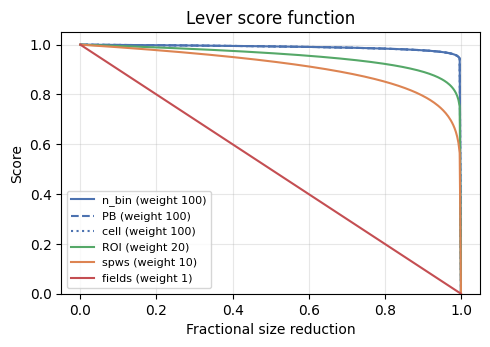

In [2]:
reductions = np.linspace(0.0, 1.0, 300)
styles = {"n_bin": "-", "PB": "--", "cell": ":", "ROI": "-", "spws": "-", "fields": "-"}
line_colors = {"n_bin": "#4C72B0", "PB": "#4C72B0", "cell": "#4C72B0",
               "ROI": "#55A868", "spws": "#DD8452", "fields": "#C44E52"}

fig, ax = plt.subplots(figsize=(5, 5/1.4))
for lever, weight in LEVER_WEIGHTS.items():
    ax.plot(reductions, [lever_score(r, weight) for r in reductions],
            linestyle=styles[lever], color=line_colors[lever], label=f"{lever} (weight {weight:g})")
ax.set_xlabel("Fractional size reduction")
ax.set_ylabel("Score")
ax.set_title("Lever score function")
ax.set_ylim(0, 1.05)
ax.legend(loc="lower left", fontsize=8)
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(PLOT_DIR / "lever_score_function.png", dpi=150)
plt.show()

## n_bin score

Score of the size reduction by channel binning (`mitigation_nbin`, 0.5 where binning is possible, 0 otherwise) with the weight of n_bin.

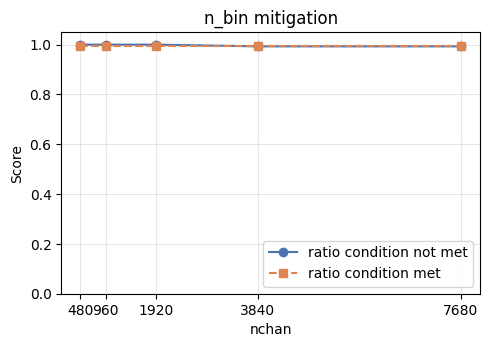

In [3]:
eligible_nchans = [480, 960, 1920, 3840, 7680]

def nbin_score(nchan, ratio_satisfied):
    return lever_score(mitigation_nbin(nchan, ratio_satisfied), LEVER_WEIGHTS["n_bin"])

score_ratio_false = [nbin_score(n, False) for n in eligible_nchans]
score_ratio_true = [nbin_score(n, True) for n in eligible_nchans]

fig, ax = plt.subplots(figsize=(5, 5/1.4))
ax.plot(eligible_nchans, score_ratio_false, marker="o", label="ratio condition not met", color="#4C72B0")
ax.plot(eligible_nchans, score_ratio_true, marker="s", linestyle="--", label="ratio condition met", color="#DD8452")
ax.set_xticks(eligible_nchans)
ax.set_xlabel("nchan")
ax.set_ylabel("Score")
ax.set_title("n_bin mitigation")
ax.set_ylim(0, 1.05)
ax.legend(loc="lower right")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(PLOT_DIR / "nbin_mitigation_scores.png", dpi=150)
plt.show()

## PB score

Score of the size reduction `mitigation_pb` with the weight of PB: 1.0 if the PB is not changed, lower the more the PB is tightened. Mosaics are never mitigated, so they stay at 1.0.

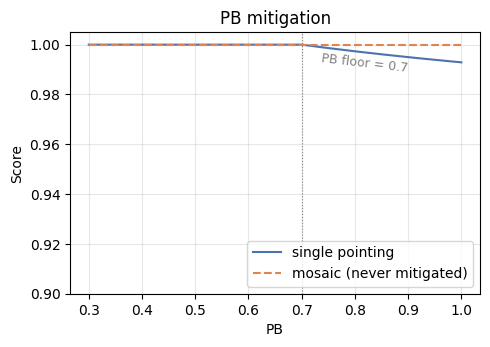

In [4]:
PB_FLOOR = 0.7

pb_values = np.linspace(0.3, 1.0, 300)
score_single_pointing = [lever_score(mitigation_pb(pb, is_mosaic=False), LEVER_WEIGHTS["PB"]) for pb in pb_values]
score_mosaic = [lever_score(mitigation_pb(pb, is_mosaic=True), LEVER_WEIGHTS["PB"]) for pb in pb_values]

fig, ax = plt.subplots(figsize=(5, 5/1.4))
ax.plot(pb_values, score_single_pointing, label="single pointing", color="#4C72B0")
ax.plot(pb_values, score_mosaic, label="mosaic (never mitigated)", color="#DD8452", linestyle="--")
ax.axvline(PB_FLOOR, color="gray", linewidth=0.8, linestyle=":")
ax.set_xlabel("PB")
ax.set_ylabel("Score")
ax.set_title("PB mitigation")
ax.set_ylim(0.9, 1.005)
ax.legend(loc="lower right")
ax.grid(alpha=0.3)
fig.tight_layout()
label_along_curve(ax, pb_values, score_single_pointing, PB_FLOOR + 0.12,
                  f"PB floor = {PB_FLOOR}", color="gray", side=-1)
fig.savefig(PLOT_DIR / "pb_mitigation_scores.png", dpi=150)
plt.show()

## hm_cell score

Score of the size reduction `mitigation_cell` with the weight of hm_cell: 1.0 if the cell is unchanged, lower the more it is enlarged.

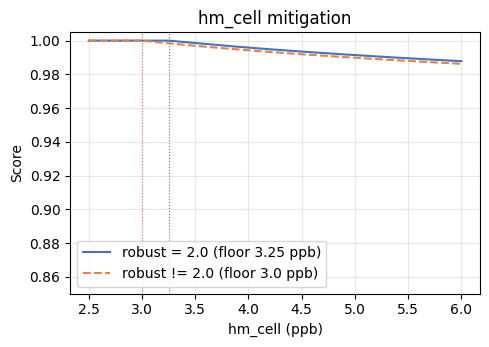

In [5]:
CELL_FLOOR_ROBUST_2 = 3.25
CELL_FLOOR_DEFAULT = 3.0

ppb_values = np.linspace(2.5, 6.0, 300)
score_robust2 = [lever_score(mitigation_cell(ppb, robust=2.0), LEVER_WEIGHTS["cell"]) for ppb in ppb_values]
score_default = [lever_score(mitigation_cell(ppb, robust=None), LEVER_WEIGHTS["cell"]) for ppb in ppb_values]

fig, ax = plt.subplots(figsize=(5, 5/1.4))
ax.plot(ppb_values, score_robust2, label="robust = 2.0 (floor 3.25 ppb)", color="#4C72B0")
ax.plot(ppb_values, score_default, label="robust != 2.0 (floor 3.0 ppb)", color="#DD8452", linestyle="--")
ax.axvline(CELL_FLOOR_ROBUST_2, color="#4C72B0", linewidth=0.8, linestyle=":")
ax.axvline(CELL_FLOOR_DEFAULT, color="#DD8452", linewidth=0.8, linestyle=":")
ax.set_xlabel("hm_cell (ppb)")
ax.set_ylabel("Score")
ax.set_title("hm_cell mitigation")
ax.set_ylim(0.85, 1.005)
ax.legend(loc="lower left")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(PLOT_DIR / "hm_cell_mitigation_scores.png", dpi=150)
plt.show()

## Spw removal score

Score of the size reduction from removing spws, with the weight of spws. Equal-sized spws are assumed here (`mitigation_spws`: `n_removed / n_total`); the planner uses the share of the actual product size in the removed spws. Nothing removed: 1.0.

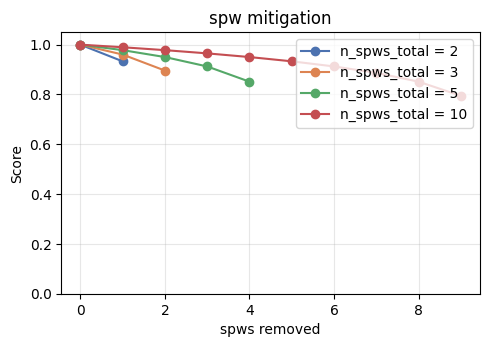

In [6]:
n_spws_total_values = [2, 3, 5, 10]
colors = ["#4C72B0", "#DD8452", "#55A868", "#C44E52"]

fig, ax = plt.subplots(figsize=(5, 5/1.4))
for n_total, color in zip(n_spws_total_values, colors):
    n_removed_values = np.arange(0, n_total)
    ax.plot(n_removed_values, [lever_score(mitigation_spws(n_total, k), LEVER_WEIGHTS["spws"]) for k in n_removed_values],
            marker="o", label=f"n_spws_total = {n_total}", color=color)
ax.set_xlabel("spws removed")
ax.set_ylabel("Score")
ax.set_title("spw mitigation")
ax.set_ylim(0, 1.05)
ax.legend(loc="upper right")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(PLOT_DIR / "spws_mitigation_scores.png", dpi=150)
plt.show()

## Field removal score

Score of the size reduction from removing fields (`mitigation_fields`: `n_removed / n_total`) with the weight of fields. Nothing removed: 1.0.

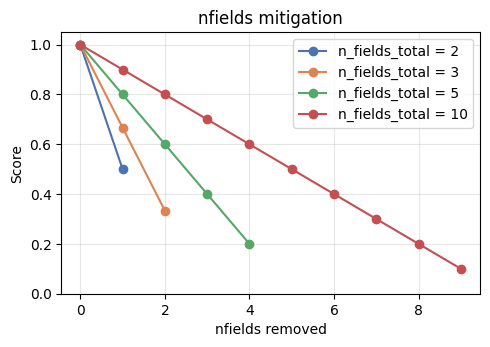

In [7]:
n_fields_total_values = [2, 3, 5, 10]

fig, ax = plt.subplots(figsize=(5, 5/1.4))
for n_total, color in zip(n_fields_total_values, colors):
    n_removed_values = np.arange(0, n_total)
    ax.plot(n_removed_values, [lever_score(mitigation_fields(n_total, n_total - k), LEVER_WEIGHTS["fields"]) for k in n_removed_values],
            marker="o", label=f"n_fields_total = {n_total}", color=color)
ax.set_xlabel("nfields removed")
ax.set_ylabel("Score")
ax.set_title("nfields mitigation")
ax.set_ylim(0, 1.05)
ax.legend(loc="upper right")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(PLOT_DIR / "nfields_mitigation_scores.png", dpi=150)
plt.show()

## ROI score

Score of the size reduction `mitigation_roi` (the removed fraction of the spw) with the weight of ROI: 1.0 for the full spw, falling to 0 as the whole spw is cut away.

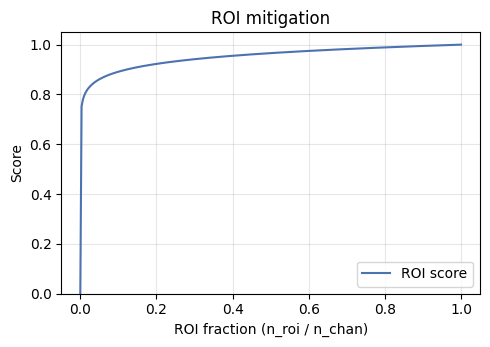

In [8]:
roi_fractions = np.linspace(0.0, 1.0, 300)
score_values = [lever_score(mitigation_roi(f, 1.0), LEVER_WEIGHTS["ROI"]) for f in roi_fractions]

fig, ax = plt.subplots(figsize=(5, 5/1.4))
ax.plot(roi_fractions, score_values, label="ROI score", color="#4C72B0")
ax.set_xlabel("ROI fraction (n_roi / n_chan)")
ax.set_ylabel("Score")
ax.set_title("ROI mitigation")
ax.set_ylim(0, 1.05)
ax.legend(loc="lower right")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(PLOT_DIR / "roi_mitigation_scores.png", dpi=150)
plt.show()